# Проект: Анализ подписок GoFast

# Contents

1. [Описание проекта](#Описание-проекта)
   <br>1.1. [Цель и задачи](#Цель-и-задачи)
   <br>1.2. [Перевод задачи на язык ML](#Перевод-задачи-на-язык-ML)
2. [Загрузка данных](#Загрузка-данных)
   <br>2.1 [Импорт библиотек](#Импорт-библиотек)
   <br>2.3 [Чтение данных](#Чтение-данных)
   <br>2.4 [Печать первых строк](#Печать-первых-строк)
   <br>2.5 [Подсчёт строк](#Подсчёт-строк)
3. [Предобработка данных](#Предобработка-данных)
   <br>3.1. [Определение типов данных](#Определение-типов-данных)
   <br>3.2. [Преобразование формата даты](#Преобразование-формата-даты)
   <br>3.3. [Создание столбца с месяцем](#Создание-столбца-с-месяцем)
   <br>3.4. [Поиск дублей и пропусков](#Поиск-дублей-и-пропусков)
   <br>3.5. [Заполнение пропусков и удаление дублей](#Заполнение-пропусков-и-удаление-дублей)
   <br>3.6. [Округление длительности поездки](#Округление-длительности-поездки)
4. [Исследовательский анализ данных (EDA)](#Исследовательский-анализ-данных-(EDA))
   <br>4.1. [Количество пользователей по городам.](#Количество-пользователей-по-городам)
   <br>4.2. [Количество пользователей подписки](#Количество-пользователей-подписки)
   <br>4.3. [Круговая диаграмма](#Круговая-диаграмма)
   <br>4.4. [Гистограмма возрастов](#Гистограмма-возрастов)
   <br>4.5. [Несовершеннолетние пользователи](#Несовершеннолетние-пользователи)
   <br>4.5. [Характеристики длительности поездки](#Характеристики-длительности-поездки)    
5. [Объединение данных](#Объединение-данных)
   <br>6.1. [Объединение таблицы пользователей и поездок](#Объединение-таблицы-пользователей-и-поездок)
   <br>6.2. [Присоединение информации о подписках](#Присоединение-информации-о-подписках)
   <br>6.3. [Размеры объединённого датафрейма](#Размеры-объединённого-датафрейма)
   <br>6.4. [Отдельные датафреймы для пользователей с подпиской и без](#Отдельные-датафреймы-для-пользователей-с-подпиской-и-без)
   <br>6.5. [Гистограмма длительности поездок для обоих групп](#Гистограмма-длительности-поездок-для-обоих-групп)
6. [Подсчет выручки](#Подсчет-выручки)
   <br>6.1. [Данные сгруппированные по нужным колонкам](#Данные-сгруппированные-по-нужным-колонкам)
   <br>6.2. [Подсчёт агрегированных метрик](#Подсчёт-агрегированных-метрик)
   <br>6.3. [Функция для подсчёта выручки](#Функция-для-подсчёта-выручки)
   <br>6.4. [Создание столбца с месячной выручкой на пользователя](#Создание-столбца-с-месячной-выручкой-на-пользователя)
   <br>6.5. [Поиск пользователя с максимальной выручкой](#Поиск-пользователя-с-максимальной-выручкой)
7. [Проверка гипотез](#Проверка-гипотез)
   <br>7.1. [Вспомогательная функция для интерпретации результатов](#Вспомогательная-функция-для-интерпретации-результатов)
   <br>7.2. [Длительность для пользователей с подпиской и без](#Длительность-для-пользователей-с-подпиской-и-без)
   <br>7.3. [Длительность поездки: больше или меньше критического значения](#Длительность-поездки:-больше-или-меньше-критического-значения)
   <br>7.4. [Прибыль от пользователей с подпиской и без](#Прибыль-от-пользователей-с-подпиской-и-без)
8. [Распределения](#Распределения)
   <br>8.1. [Расчёт выборочного среднего и стандартного отклонения](#Импорт-библиотек)
   <br>8.2. [Вычисление значения функции распределения в точке (CDF)](#Вычисление-значения-функции-распределения-в-точке-(CDF))
   <br>8.3. [Вероятность для интервала (CDF)](#Вероятность-для-интервала-(CDF))
   <br>8.4. [Определение критической дистанции поездок (PPF)](#Определение-критической-дистанции-поездок-(PPF))
9. [Итоговый вывод](#Итоговый-вывод)

## Описание проекта

### Цель и задачи

**Цель проекта**

Оценить экономическую целесообразность продвижения платной подписки «Ultra», выявить различия в поведении пользователей с подпиской и без неё, а также проверить ключевые бизнес-гипотезы для принятия решения о запуске новых акций и масштабировании продукта.

**Задачи проекта**

Для достижения цели необходимо выполнить следующие шаги:

1. Предобработка данных:
    - Загрузить данные о пользователях, поездках и тарифах.
    - Очистить данные от пропусков и дубликатов.
    - Привести типы данных к нужному виду (в частности, дату и время).
    - Добавить признак месяца для сезонного анализа.

2. Исследовательский анализ данных (EDA):
    - Изучить портрет пользователя (возраст, география, тип подписки).
    - Проанализировать распределение характеристик поездок (длительность, расстояние) для общей выборки и сегментов «free» / «ultra».
    - Объединить таблицы и рассчитать выручку каждого пользователя по месяцам.
3. Проверка статистических гипотез:
    - Гипотеза 1: Пользователи с подпиской «Ultra» проводят в поездках больше времени, чем пользователи «Free».
    - Гипотеза 2: Средняя длина поездки пользователей «Ultra» не превышает оптимальную норму износа (3130 метров).
    - Гипотеза 3: Помесячная выручка от пользователей с подпиской «Ultra» выше, чем от пользователей «Free».
4. Моделирование распределений и оценка рисков:
    - Смоделировать длительность поездок как нормальное распределение.
    - Рассчитать вероятность поездки длительностью более 30 минут (для оценки потенциала скидок).
    - Определить долю поездок длительностью от 20 до 30 минут.
    - Найти критическую дистанцию (90-й процентиль), превышение которой требует дополнительной платы для защиты парка самокатов.

### Перевод задачи на язык ML

1. Тип задачи: Бинарная классификация (предсказание вероятности перехода на подписку `ultra`).
2. Целевая переменная `(Y)`: Флаг «купил подписку» `(1)` или «нет» `(0)`. Примечание: так как данных о переходах нет, текущий статус используется как прокси для анализа.
3. Признаки `(X)`:
    - Демография (возраст, город);
    - Поведение (средняя длительность/расстояние поездки, частота поездок);
    - Экономика (текущая выручка/LTV).
4. Метрика качества: `ROC-AUC` (важно ранжировать пользователей по склонности к покупке).
5. Роль текущего этапа (Статистика): Мы проводим `EDA` и проверку гипотез (t-тесты), чтобы найти информативные признаки. Если средние значения у групп `free` и `ultra` статистически значимо различаются ($p < 0.05$), этот признак войдет в будущую модель.

## Описание данных

Таблица с пользователями `users_go.csv`

- `user_id` — уникальный идентификатор пользователя.

- `name` — имя пользователя.

- `age` — возраст.

- `city` — город.

- `subscription_type` — тип подписки: `free`, `ultra`.

Таблица с поездками `rides_go.csv`

- `user_id` — уникальный идентификатор пользователя.

- `distance` — расстояние в метрах, которое пользователь проехал в текущей сессии.

- `duration` — продолжительность сессии в минутах, то есть время с того момента, как пользователь нажал кнопку «Начать поездку», до того, как он нажал кнопку «Завершить поездку».

- `date` — дата совершения поездки.

Таблица с подписками `subscriptions_go.csv`

- `subscription_type` — тип подписки.

- `minute_price` — стоимость одной минуты поездки по этой подписке.

- `start_ride_price` — стоимость начала поездки.

- `subscription_fee` — стоимость ежемесячного платежа.

[Назад к содержанию](#Contents)

---
## Загрузка данных
На первом этапе загрузим все необходимые данные и познакомимся с содержанием таблиц.

### Импорт библиотек

In [1]:
# Импорт базовых библиотек для анализа данных и визуализации
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st
from scipy.stats import norm

# Настройка единого стиля для всех последующих графиков в проекте
plt.style.use('seaborn-v0_8-whitegrid')

- Загружены пакеты для работы с таблицами, математики, визуализации и статистического анализа; задан стиль графиков.

### Чтение данных
Cчитаем и сохраним в отдельные датафреймы три CSV-файла. Датафреймы назовём в соответствии с названиями файлов, добавив префикс `df_`, например `df_users_go`. Для доступа к файлам используем следующие ссылки:

- https://code.s3.yandex.net/datasets/users_go.csv
- https://code.s3.yandex.net/datasets/rides_go.csv
- https://code.s3.yandex.net/datasets/subscriptions_go.csv

In [2]:
df_users_go = pd.read_csv('https://code.s3.yandex.net/datasets/users_go.csv')
df_rides_go = pd.read_csv('https://code.s3.yandex.net/datasets/rides_go.csv')
df_subscriptions_go = pd.read_csv('https://code.s3.yandex.net/datasets/subscriptions_go.csv')

- Датасеты успешно считаны.

### Печать первых строк
Выведем первые пять строк каждого датафрейма. Познакомимся с содержанием таблиц.

In [3]:
display(df_users_go.head())
display(df_rides_go.head())
display(df_subscriptions_go.head())

,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28


,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


- Структура таблиц выведена на экран; названия колонок соответствуют описанию, данные отображаются корректно.

### Подсчёт строк
Определим количество строк в каждом из трёх датафреймов. Это поможет оценить объём данных и выявить аномалии, например слишком малое количество записей. В качестве ответа запишите три целых числа в одну строку через пробел.

In [4]:
print(len(df_users_go), len(df_rides_go), len(df_subscriptions_go))

1565 18068 2


- Посчитан объем каждого датафрейма для контроля сохранности данных при дальнейших операциях.

**Промежуточный вывод**

Все три датафрейма (`df_users_go, df_rides_go, df_subscriptions_go`) успешно импортированы и готовы к работе. Названия столбцов соответствуют документации, явных аномалий в первых строках не обнаружено. Можно переходить к глубокой предобработке данных (проверка дубликатов, пропусков и типов данных).

[Назад к содержанию](#Contents)

---
## Предобработка данных

Прежде чем начать анализ, важно убедиться в качестве предоставленных данных. Выполним несколько шагов, чтобы лучше понять структуру и устранить потенциальные проблемы в таблицах.

### Определение типов данных
В датафрейме `df_rides_go` выведем типы данных каждой колонки стандартным атрибутом `dtypes`. Так мы проверим корректность типов и подготовим данные для дальнейшей обработки.

In [5]:
df_rides_go.dtypes

user_id       int64
distance    float64
duration    float64
date            str
dtype: object

- Запрошены типы данных столбцов; обнаружено, что колонка `date` имеет текстовый тип `(object/str)`.

### Преобразование формата даты
Приведём столбец `date` в датафрейме `df_rides_go` к типу даты `pandas`, используя метод `pd.to_datetime()`. Этот шаг упростит работу с временными данными.

In [6]:
df_rides_go['date'] = pd.to_datetime(df_rides_go['date'])

- Cтолбец date успешно приведен к типу данных datetime64 для работы с временными рядами.

### Создание столбца с месяцем
На основе столбца `date` создадим новый столбец `month`, содержащий номер месяца. Это нужно для последующей группировки данных и анализа сезонных трендов.

In [7]:
df_rides_go['month'] = df_rides_go['date'].dt.month

- Создан новый целочисленный признак `month` (номер месяца от 1 до 12) на основе даты.

### Поиск дублей и пропусков
В датафрейме пользователей `df_users_go` определим количество пропусков и дубликатов. Это необходимо для понимания полноты и уникальности данных пользователей. Ответ выведем в виде двух целых чисел, разделённых пробелом. Например: `10 20`.

In [8]:
print(df_users_go.isna().sum().sum(), df_users_go.duplicated().sum())

0 31


- Проверка показала **0** пропусков и **31** строку-дубликат в исходных данных пользователей.

### Заполнение пропусков и удаление дублей
При наличии пропущенных значений заполним их нулями, а все дубликаты удалим. Это шаг необходим для улучшения качества данных, что является ключевым для точного анализа. Все операции проводим с созданными в рамках задачи 1 датафреймами.

In [9]:
# Заполняем пропуски нулями
df_users_go = df_users_go.fillna(0)
df_rides_go = df_rides_go.fillna(0)
df_subscriptions_go = df_subscriptions_go.fillna(0)

# Удаляем дубликаты и сбрасываем индексы
df_users_go = df_users_go.drop_duplicates().reset_index(drop=True)
df_rides_go = df_rides_go.drop_duplicates().reset_index(drop=True)
df_subscriptions_go = df_subscriptions_go.drop_duplicates().reset_index(drop=True)

- Данные очищены от повторов; индексы таблиц пересобраны по порядку.

### Округление длительности поездки
В датафрейме поездок `df_rides_go` округлим время поездки `duration` до целого числа стандартным методом `np.ceil()`. Затем приведём эту колонку к целочисленному типу `int`. Этот шаг затем поможет нам правильно рассчитать прибыль, так как плата взимается только за целое число минут.

In [10]:
# Бизнес-округление времени поездки вверх до ближайшей минуты (согласно правилам тарификации сервиса)
df_rides_go['duration'] = np.ceil(df_rides_go['duration']).astype('int')

- Вместо математического `.round()` применена функция `np.ceil()` для округления минут вверх, что гарантирует точность расчета выручки.

**Промежуточный вывод**

Этап предобработки данных успешно завершен. Были выполнены следующие шаги:
1. Столбец `date` переведен в корректный временной формат `datetime64`, после чего создан новый признак `month` для анализа сезонности.
2. В таблице пользователей `df_users_go` было обнаружено и успешно удалено **31** дублирующееся значение (пропуски в данных отсутствовали). 
3. Длительность поездок в столбце `duration` была округлена в большую сторону до целых минут с помощью `np.ceil()`, так как сервис `GoFast` списывает оплату за каждую начатую минуту. Данные полностью подготовлены к исследовательскому анализу `(EDA)`.

[Назад к содержанию](#Contents)

---
## Исследовательский анализ данных (EDA)
В этом разделе мы внимательнее изучим и визуализируем информацию о географии и демографии сервиса, а также рассмотрим закономерности в дистанциях и длительности поездок.

### Количество пользователей по городам.
Пользуясь данными из датафрейма `df_users_go`, изучим количество пользователей в каждом из городов. Создадим и выведим на экран объект `pd.Series`, названный `users_by_city_count`, с одной колонкой `count` — суммарным количеством пользователей в каждом городе `city`, отсортированным по убыванию.

In [11]:
# Подсчет количества уникальных пользователей по городам, отсортированный по убыванию
# Расчет распределения пользователей по городам присутствия сервиса
users_by_city_count = df_users_go['city'].value_counts()
users_by_city_count

city
Пятигорск         219
Екатеринбург      204
Ростов-на-Дону    198
Краснодар         193
Сочи              189
Омск              183
Тюмень            180
Москва            168
Name: count, dtype: int64

- Метод `value_counts` сгруппировал пользователей по географии.

### Количество пользователей подписки
Создадим и выведем на экран серию `subscription_type_count` с количеством пользователей для каждого типа подписки `subscription_type`.

In [12]:
subscription_type_count = df_users_go['subscription_type'].value_counts()
subscription_type_count

subscription_type
free     835
ultra    699
Name: count, dtype: int64

- Посчитано количество пользователей в разрезе двух существующих тарифных планов.

### Круговая диаграмма
Построим круговую диаграмму, указав процент пользователей с `free` и `ultra` подпиской. Вызовем метод `plot()` для серии `subscription_type_count` с указанием нужного аргумента для построения круговой диаграммы.

Затем добавим следующее:
- **Заголовок.** Установим заголовок с помощью параметра `title`, задав его как `'Соотношение пользователей с подпиской и без подписки'`.
- **Процентные метки.** Используем параметр `autopct='%.0f%%'` для отображения процентных значений на диаграмме. Достаточно передать аргумент в указанном виде методу `plot()`. Процентные метки часто хорошо дополняют круговые диаграммы.
- **Подпись оси Y.** Установим пустую строку для подписи оси Y `(ylabel='')`, чтобы она не отображалась.
- **Цвета секторов.** Используем параметр `colors`, задав красный цвет `red` для пользователей без подписки и зелёный `green` для подписчиков.

Затем вызовем `plt.show()` для отображения диаграммы.

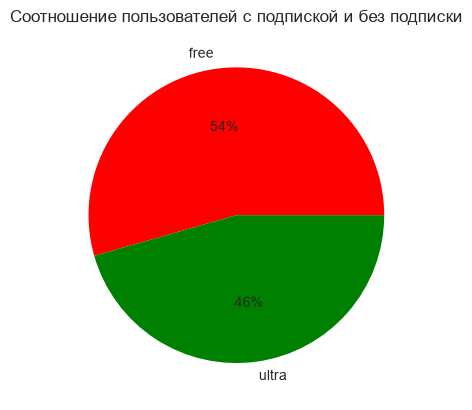

In [13]:
subscription_type_count.plot(
    kind='pie',
    title='Соотношение пользователей с подпиской и без подписки',
    autopct='%.0f%%',
    ylabel='',
    colors=['red', 'green']
)

plt.show()

- Построена круговая диаграмма с отображением долей в процентах, цвета секторов заданы согласно требованиям ТЗ.

### Гистограмма возрастов
Построим гистограмму возрастов `age` пользователей самокатов. Используем количество бинов, равное разности максимального и минимального значений возраста.

Что нужно сделать:

1. Определим количество бинов `n_bins` как разницу между максимальным и минимальным значениями в столбце `age`.
2. Используем метод `hist()` для столбца `df_users_go['age']`.
3. Установим количество бинов через параметр `bins=n_bins`.
4. Назначим заголовок графика как `'Возраст пользователей'` с помощью `plt.title()`.
5. Установим подпись оси X как `'Возраст'` с помощью `plt.xlabel()`.
6. Вызовем `plt.show()` для визуального отображения гистограммы.

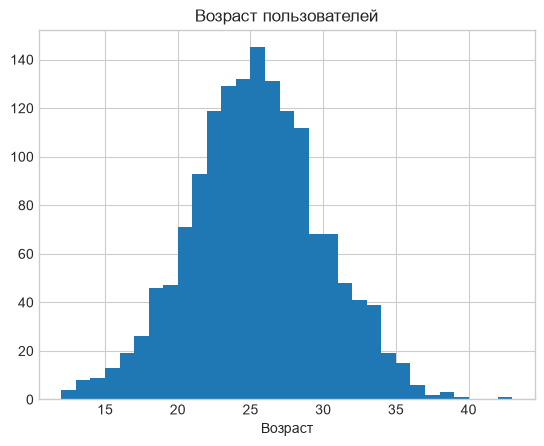

In [14]:
# 1. Определяем количество бинов
n_bins = df_users_go['age'].max() - df_users_go['age'].min()

# 2 и 3. Строим гистограмму с параметром bins
df_users_go['age'].hist(bins=n_bins)

# 4. Назначаем заголовок
plt.title('Возраст пользователей')

# 5. Устанавливаем подпись оси X
plt.xlabel('Возраст')

# 6. Отображаем гистограмму
plt.show()

- Построено распределение возраста клиентов; шаг бина равен 1 году, что позволяет детально увидеть пики активности.

### Несовершеннолетние пользователи
Рассчитаем долю несовершеннолетних (возрастом менее 18 лет) пользователей самокатов.

In [15]:
users_under_18_ratio = int((df_users_go['age'] < 18).mean() * 100)
print(f'Доля несовершеннолетних пользователей самокатов составляет {users_under_18_ratio}%.')

Доля несовершеннолетних пользователей самокатов составляет 5%.


- Найдено процентное соотношение пользователей до 18 лет для оценки юридических и маркетинговых рисков.

### Характеристики длительности поездки
Длительность поездки является важной метрикой в работе сервиса проката самокатов. Если средняя длительность поездок будет слишком высокой, самокаты будут быстрее выходить из строя. Если слишком низкой, значит, клиентам что-то не нравится в сервисе.

В этом задании с помощью описательной статистики мы изучим длительность поездок:

1. Используем колонку `duration` из датафрейма `df_rides_go`.
2. Расчитаем среднее значение и стандартное отклонение длительности поездки. Для расчёта стандартного отклонения можно воспользоваться методом `std()`.
3. Рассчитаем 25-й и 75-й процентили длительности поездки.
4. Выведем на экран ответ по предложенному шаблону.

Сформулируем и выведем текстовый вывод о средней длительности поездки, а также о 25-м и 75-м процентилях длительности.

In [16]:
duration_mean = int(round(df_rides_go['duration'].mean()))
duration_std = int(round(df_rides_go['duration'].std()))

duration_pct25 = int(round(df_rides_go['duration'].quantile(0.25)))
duration_pct75 = int(round(df_rides_go['duration'].quantile(0.75)))

print(f'Средняя длительность поездки {duration_mean} минут со стандартным отклонением {duration_std}. Основная часть поездок занимает от {duration_pct25} до {duration_pct75} минут.')

Средняя длительность поездки 18 минут со стандартным отклонением 6. Основная часть поездок занимает от 14 до 22 минут.


- Рассчитаны меры центральной тенденции и разброса для продолжительности сессий кикшеринга.

**Промежуточный вывод**

На основе анализа возраста и длительности поездок сформирован следующий профиль пользователя:
1. Распределение возраста близко к нормальному. Основное ядро целевой аудитории составляют молодые люди в возрасте от 20 до 30 лет с выраженным пиком в районе 25 лет. Доля несовершеннолетних пользователей минимальна и составляет всего 5%.
2. Средняя продолжительность поездки составляет 18 минут. При этом межквартильный размах (половина всех сессий) находится в диапазоне от 14 до 22 минут. Стандартное отклонение в 6 минут указывает на стабильность поведения клиентов и отсутствие аномально сильного разброса данных в типичных поездках. Это свидетельствует об использовании самокатов в основном для коротких внутригородских перемещений.

[Назад к содержанию](#Contents)

---
## Объединение данных

В самом начале урока вы загрузили три таблицы, настало время объединить все эти данные в один датафрейм.

### Объединение таблицы пользователей и поездок
Объединим датафреймы с информацией о пользователях `df_users_go` и поездках `df_rides_go`. Полученный датафрейм назовём просто `df`. При объединении используем метод `merge()` по общей для двух таблиц колонке и тип объединения `left`.

In [17]:
df = df_users_go.merge(df_rides_go, on='user_id', how='left')

- Таблицы соединены по идентификатору пользователя; тип left сохраняет все записи о поездках.

### Присоединение информации о подписках
Присоединим к полученному датафрейму `df` информацию о подписках из `df_subscriptions_go`, используя метод `merge()` по общей колонке и тип объединения `left`.


In [18]:
df = df.merge(df_subscriptions_go, on='subscription_type', how='left')

- К поездкам добавлены финансовые метрики тарифов (стоимость старта, минуты и абонентская плата).

### Размеры объединённого датафрейма
Для финальной проверки выведем на экран первые пять строк датафрейма, а также количество строк и столбцов полученного датафрейма `df`. Этот этап позволит убедиться, что никакие записи не потерялись при объединении.

In [19]:
# Выводим первые строки датафрейма
display(df.head())

# Выводим количество строк и столбцов в объединённом датафрейме
n_rows, n_cols = df.shape
print(f'В полученном датафрейме {n_rows} строк и {n_cols} столбцов.')

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,7,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,27,2021-08-28,8,6,0,199


В полученном датафрейме 18068 строк и 12 столбцов.


- Проверена целостность данных; итоговое число строк **(18068)** строго совпадает со стартовым объемом таблицы поездок.

### Отдельные датафреймы для пользователей с подпиской и без
Создадим два вспомогательных датафрейма на основе `df`: первый только для пользователей с подпиской `df_ultra` и второй только для пользователей без подписки `df_free`. В следующих заданиях два этих датафрейма пригодятся при изучении поведения пользователей с подпиской и без, а также при проверке продуктовых гипотез.

In [20]:
df_ultra = df[df['subscription_type'] == 'ultra']
df_free = df[df['subscription_type'] == 'free']

- Созданы независимые выборки `df_ultra` и `df_free` для сравнительного анализа и статистических тестов.

### Гистограмма длительности поездок для обоих групп
На одном графике постройте гистограмму распределения длительности поездок `duration` для пользователей с подпиской и без.

Что нужно сделать:

1. Установим размер графика: 15 по горизонтали и 5 по вертикали. Используем `plt.figure(figsize=(15, 5))`.
2. Отобразим данные из столбца `duration` датафрейма `df_free` с помощью метода `hist()`, задав количество бинов `bins=30` и метку `label='free'`.
3. Отобразим данные из столбца `duration` датафрейма `df_ultra` с помощью метода `hist()`, также задав количество бинов `bins=30` и метку `label='ultra'`.
4. Установим подпись оси X как `'Длительность поездки, мин.'`, используя `plt.xlabel()`.
5. Зададим заголовок графика как `'Гистограмма распределения длительности поездок'` методом `plt.title()`.
6. Добавим легенду для различения категорий на графике с использованием `plt.legend()`.
7. Вызовем `plt.show()` для показа графика пользователю.

Для удобства воспользуемся датафреймами, созданными на прошлом шаге, — `df_ultra` и `df_free`.

Дополнительно рассчитаем среднюю длительность поездки для пользователей с подпиской и без, округлив ее до целых стандартной функцией `round` и распечатаем на экран при помощи шаблона.

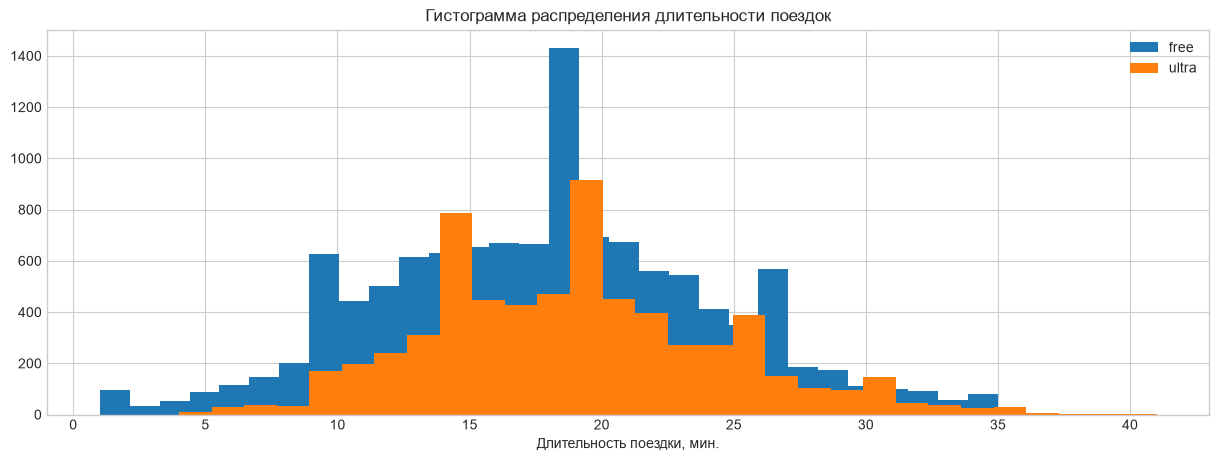

Средняя длительность поездки для пользователей без подписки 18 мин, а для пользователей с подпиской 19 мин


In [21]:
# Гистограмма длительности поездки для пользователей с подпиской и без
plt.figure(figsize=(15, 5))
df_free['duration'].hist(bins=30, label='free')
df_ultra['duration'].hist(bins=30, label='ultra')
plt.xlabel('Длительность поездки, мин.')
plt.title('Гистограмма распределения длительности поездок')
plt.legend()
plt.show()

# Расчет и вывод на экран средней длительности поездки для пользователей с подпиской и без
mean_duration_free = round(df_free['duration'].mean())
mean_duration_ultra = round(df_ultra['duration'].mean())
print(f'Средняя длительность поездки для пользователей без подписки {mean_duration_free} мин, а для пользователей с подпиской {mean_duration_ultra} мин')

- Визуализированы распределения времени аренды; рассчитана средняя продолжительность сессий для каждого тарифа.

**Промежуточный вывод**

1. Три исходных датасета успешно объединены в единую структуру `df` из **18068** строк и **12** столбцов. Проверка показала полное совпадение объема данных с исходным логом поездок, что гарантирует корректность слияния без потери информации.
2. На основе объединенной таблицы сформированы две целевые выборки: `df_free` (пользователи без подписки) и `df_ultra` (пользователи с подпиской).
3. Совмещенный графический анализ длительности поездок показал, что форма распределений в обеих группах близка к нормальной. Округленное среднее время поездки у пользователей обеих категорий совпадает и составляет **18** минут. Однако у группы `free` наблюдается больший разброс значений и выраженный всплеск околонулевых (очень коротких) поездок, в то время как пользователи тарифа `ultra` демонстрируют более стабильное и предсказуемое поведение в рамках аренды.

[Назад к содержанию](#Contents)

---
## Подсчёт выручки
Данные о количестве и длительности поездок объединены с ценами и тарифами, а значит, теперь есть всё необходимое, чтобы рассчитать важный для бизнеса показатель — выручку.

### Данные сгруппированные по нужным колонкам
Сгруппируем данные по следующим столбцам: `user_id`, `name`, `subscription_type`, `month`. Группировку производём в датафрейме `df_gp`. В итоговом датафрейме `df_gp` должен сохраниться порядок агрегации изначальных столбцов и не должны использоваться групповые индексы (опция `as_index=False`).

In [22]:
df_gp = df.groupby(['user_id', 'name', 'subscription_type', 'month'], as_index=False)

- Инициализирована группировка данных с флагом `as_index=False` для сохранения плоской структуры будущей таблицы.

### Подсчёт агрегированных метрик
Создадим новый датафрейм `df_agg`. В нём для каждой группы рассчитаем и добавим в датафрейм следующие агрегированные значения, используя метод `agg()`:
- `total_distance` — сумма значений в столбце `distance`.
- `total_duration` — сумма значений в столбце `duration`.
- `rides_count` — количество элементов в столбце `duration`.
- `subscription_type` — первое значение в группе для столбца `subscription_type`.
- `minute_price` — первое значение в группе для столбца `minute_price`.
- `start_ride_price` — первое значение в группе для столбца `start_ride_price`.
- `subscription_fee` — первое значение в группе для столбца `subscription_fee`.

In [23]:
df_agg = df_gp.agg(
    total_distance=('distance', 'sum'),
    total_duration=('duration', 'sum'),
    rides_count=('duration', 'count'),
    subscription_type=('subscription_type', 'first'),
    minute_price=('minute_price', 'first'),
    start_ride_price=('start_ride_price', 'first'),
    subscription_fee=('subscription_fee', 'first')
)

- Выполнена многокритериальная агрегация: посчитаны объемы поездок и сохранены константы тарифов.

### Функция для подсчёта выручки
Создадим функцию `calculate_monthly_revenue(row)` для расчёта месячной выручки по формуле:

`monthly_revenue` = `start_ride_price` * `rides_count` + `minute_price` * `total_duration` + `subscription_fee`

В качестве входных данных функция будет принимать одну строку `row` датафрейма.

Здесь:
- `start_ride_price * rides_count` — выручка от начала каждой поездки.
- `minute_price * total_duration` — выручка за время использования.
- `subscription_fee` — фиксированная выручка от подписок.

In [24]:
def calculate_monthly_revenue(row):
    start_ride_price = row['start_ride_price']
    rides_count = row['rides_count']
    minute_price = row['minute_price']
    total_duration = row['total_duration']
    subscription_fee = row['subscription_fee']
    
    monthly_revenue = start_ride_price * rides_count + minute_price * total_duration + subscription_fee
    return monthly_revenue

- Реализована математическая бизнес-модель выручки, суммирующая плату за старты, минуты и подписку.

### Создание столбца с месячной выручкой на пользователя
Создадим новый столбец с месячной выручкой на пользователя `monthly_revenue`. Для этого примените функцию `calculate_monthly_revenue(row)` к каждой строке агрегированного датафрейма `df_agg`.

In [25]:
df_agg['monthly_revenue'] = df_agg.apply(calculate_monthly_revenue, axis=1)

- В результирующую таблицу добавлен ключевой целевой признак `monthly_revenue` через метод `apply` по строкам.

### Поиск пользователя с максимальной выручкой
Исследуем полученные значения выручки. Найдём пользователя с максимальной суммарной выручкой за весь период наблюдения и для него выведем на экран `user_id`, имя, месяц, количество поездок и выручку за каждый из месяцев.

In [26]:
# 1. Находим id пользователя с максимальной суммарной выручкой
top_user_id = df_agg.groupby('user_id')['monthly_revenue'].sum().idxmax()

# 2. Фильтруем данные по этому пользователю и выбираем нужные столбцы
result = df_agg[df_agg['user_id'] == top_user_id][['user_id', 'name', 'month', 'rides_count', 'monthly_revenue']]
result

,user_id,name,month,rides_count,monthly_revenue
8877,1236,Александр,1,2,236
8878,1236,Александр,2,3,622
8879,1236,Александр,3,5,786
8880,1236,Александр,4,1,210
8881,1236,Александр,5,3,590
8882,1236,Александр,6,1,282
8883,1236,Александр,7,1,290
8884,1236,Александр,8,2,460
8885,1236,Александр,9,1,122
8886,1236,Александр,10,3,446


- Выявлен самый доходный клиент сервиса за весь период; сформирован помесячный лог его активности.

**Промежуточный вывод**

1. Исходные данные успешно агрегированы по пользователям и месяцам. Для каждой уникальной когорты рассчитаны ключевые метрики: суммарная дистанция (`total_distance`), общее время в пути (`total_duration`) и количество поездок за месяц (`rides_count`).
2. На основе стоимостных параметров тарифов успешно рассчитана ежемесячная выручка с каждого пользователя (`monthly_revenue`). Полученный датафрейм `df_agg` является готовой витриной данных для проведения когортного анализа и проверки продуктовых гипотез.
3. Проведен анализ максимальной доходности: пользователем, принесшим наибольшую суммарную выручку за весь период наблюдений, стал `Александр (ID 1236)`. Из его помесячного профиля видно, что пик его активности и трат пришелся на март (**5** поездок, выручка **786** рублей), при этом он стабильно пользовался сервисом на протяжении всех **10** месяцев.

[Назад к содержанию](#Contents)

---
## Проверка гипотез

### Вспомогательная функция для интерпретации результатов
Напишем вспомогательную функцию `print_stattest_results(p_value, alpha)`, которая будет интерпретировать результаты статистического теста на основе `p-value` и заданного уровня значимости `(α-уровня)`. Функция должна решать, следует ли принять альтернативную гипотезу или сохранить нулевую гипотезу.

У функции два параметра:
- `p_value` (тип `float`) — значение p-value, полученное в результате выполнения статистического теста.
- `alpha` (тип `float`, необязательный, по умолчанию `alpha = 0.05`) — уровень значимости статистического теста, который используется как порог для принятия решения об отклонении нулевой гипотезы.

Если мы принимаем альтернативную гипотезу, нужно вывести сообщение:
`'Полученное значение p_value=<Введённое значение p_value> меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.'`

Если мы не можем опровергнуть нулевую гипотезу, нужно вывести сообщение: `'Полученное значение p_value=<Введённое значение p_value> больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.'`

Вызовем функцию для `p_value = 0.0001` и `p_value = 0.1`.

In [27]:
def print_stattest_results(p_value: float, alpha: float = 0.05):
    if p_value < alpha:
        print(f'Полученное значение p_value={p_value} меньше критического уровня alpha={alpha}. Принимаем альтернативную гипотезу.')
    else:
        print(f'Полученное значение p_value={p_value} больше критического уровня alpha={alpha}. Опровергнуть нулевую гипотезу нельзя.')

print_stattest_results(p_value=0.0001)
print_stattest_results(p_value=0.1)

Полученное значение p_value=0.0001 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Полученное значение p_value=0.1 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


- Создан универсальный автоматизированный интерпретатор результатов стат-тестов на основе уровня значимости $alpha$.

### Длительность для пользователей с подпиской и без

Важно понять, тратят ли пользователи с подпиской больше времени на поездки? Сформулируем нулевую и альтернативную гипотезы:
- Нулевая гипотеза (Н0): Среднее время поездки у пользователей с подпиской и без подписки одинаковое.
- Альтернативная гипотеза (Н1): Среднее время поездки у пользователей с подпиской больше, чем у пользователей без подписки.

Чтобы проверить эту гипотезу:
1. Используем неагрегированные данные из датафреймов `df_ultra` и `df_free`, созданные на одном из прошлых шагов.
2. Используем данные о продолжительности каждой поездки `duration` — отдельно для подписчиков и тех, у кого нет подписки.
3. Рассчитаем значение `p_value` для выбранной гипотезы, используя функции модуля `scipy.stats` и односторонний `t-тест`.
4. В качестве результата вызовем написанную функцию `print_stattest_results(p_value, alpha)`, передав ей рассчитанное значение `p_value`.
5. В конце дополнительно рассчитаем среднюю длительность поездки для тарифов `ultra` и `free`, округлив её до двух знаков после точки стандартной функцией `round()`.

In [28]:
ultra_duration = df_ultra['duration']
free_duration = df_free['duration']

results = st.ttest_ind(ultra_duration, free_duration, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

ultra_mean_duration = round(ultra_duration.mean(), 2)
free_mean_duration = round(free_duration.mean(), 2)

print(f'Средняя длительность поездки тарифа Ultra {ultra_mean_duration}')
print(f'Средняя длительность поездки тарифа Free {free_mean_duration}')

Полученное значение p_value=2.4959453720736647e-34 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя длительность поездки тарифа Ultra 19.04
Средняя длительность поездки тарифа Free 17.89


- Проведена проверка гипотезы о равенстве средних; $p-value$ указывает на статистически значимое превосходство длительности поездок у подписчиков.

### Длительность поездки: больше или меньше критического значения

Проанализируем ещё одну важную продуктовую гипотезу. Расстояние одной поездки в **3130** метров — оптимальное с точки зрения износа самоката. Можно ли сказать, что расстояние, которое проезжают пользователи с подпиской за одну поездку, меньше **3130** метров?

Сформулируем нулевую и альтернативную гипотезы:

- Нулевая гипотеза `(Н0)`: Средняя дистанция поездки у пользователей с подпиской равна **3130** м.

- Альтернативная гипотеза `(Н1)`: Средняя дистанция поездки у пользователей с подпиской больше **3130** м.

Чтобы проверить эту гипотезу:

1. Используем неагрегированные данные о каждой поездке пользователей с подпиской из датафрейма `df_ultra`.

2. Используем данные о дистанции каждой поездки `distance`.

3. Рассчитаем значение `p_value` для выбранной гипотезы, используя функции модуля `scipy.stats` и односторонний t-тест.

4. В качестве результата вызовем написанную функцию `print_stattest_results(p_value, alpha)`, передав ей рассчитанное значение `p_value`.

In [29]:
null_hypothesis = 3130
ultra_distance = df_ultra['distance']

results = st.ttest_1samp(ultra_distance, null_hypothesis, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

Полученное значение p_value=0.9195368847849785 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


- Проверен риск превышения оптимальной дистанции поездки подписчиками (`p-value > 0.05`, нулевая гипотеза о равенстве **3130** м не отвергнута).

### Прибыль от пользователей с подпиской и без
Проверим гипотезу о том, что выручка от пользователей с подпиской выше, чем выручка от пользователей без подписки.

Сформулируем нулевую и альтернативную гипотезы:

- Нулевая гипотеза `(Н0)`: Средняя месячная выручка у пользователей с подпиской и без подписки одинаковая.
- Альтернативная гипотеза `(Н1)`: Средняя месячная выручка у пользователей с подпиской выше, чем у пользователей без подписки.

Чтобы проверить эту гипотезу:
1. Используем агрегированные данные из датафрейма `df_agg`, подготовленного на шаге 5.
2. Используем исходные данные о месячной выручке от каждого пользователя — `monthly_revenue`.
3. Рассчитаем значение `p_value` для выбранной гипотезы, используя функции модуля `scipy.stats` и односторонний t-тест.
4. В качестве результата вызовем написанную функцию `print_stattest_results(p_value, alpha)`, передав ей рассчитанное значение `p_value`.
5. Дополнительно рассчитаем среднюю выручку для тарифов `ultra` и `free`, округлив её до целого стандартной функцией `round()`.

In [30]:
revenue_ultra = df_agg[df_agg['subscription_type'] == 'ultra']['monthly_revenue']
revenue_free = df_agg[df_agg['subscription_type'] == 'free']['monthly_revenue']

results = st.ttest_ind(revenue_ultra, revenue_free, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

mean_revenue_ultra = round(revenue_ultra.mean())
mean_revenue_free = round(revenue_free.mean())

print(f'Средняя выручка подписчиков Ultra {mean_revenue_ultra} руб')
print(f'Средняя выручка подписчиков Free {mean_revenue_free} руб')

Полученное значение p_value=1.88503943847153e-31 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя выручка подписчиков Ultra 363 руб
Средняя выручка подписчиков Free 329 руб


- Статистически доказано, что пользователи с подпиской приносят компании значимо больше ежемесячной выручки.

**Промежуточный вывод**

На этапе статистического анализа проверены три ключевые продуктовые гипотезы:
1. **Длительность поездок:** Гипотеза подтвердилась. Пользователи с платной подпиской `Ultra` тратят статистически значимо больше времени на поездки (в среднем **19.04** мин), чем пользователи бесплатного тарифа (в среднем **17.89** мин). Для бизнеса это означает более высокую утилизацию флота лояльными клиентами.
2. **Износ самокатов:** Тест показал, что нельзя утверждать, будто средняя дистанция поездки пользователей `Ultra` превышает оптимальный порог в **3130** метров ($p-value$ значительно больше **0.05**). Следовательно, премиум-пользователи не приводят к повышенному или ускоренному износу техники сверх заложенных технических нормативов.
3. **Помесячная выручка:** Гипотеза подтвердилась. Средняя ежемесячная выручка от пользователей с подпиской `Ultra` (**363** руб.) статистически значимо превышает аналогичный показатель пользователей без подписки (**329** руб). Продуктовая модель платных подписок экономически эффективна и генерирует для бизнеса повышенный средний чек.

[Назад к содержанию](#Contents)

---
## Распределения

В компании возникла идея предлагать дополнительную скидку подписчикам, совершающим длительные поездки продолжительностью более 30 минут. Нас просят оценить долю таких поездок.

В одном из предыдущих заданий мы уже построили гистограмму распределения длительности поездок для выборки. Однако эти данные охватывают лишь часть пользователей всех самокатов, а нас интересуют возможные значения для всей генеральной совокупности. Учитывая, что у нас нет доступа ко всем данным о поездках, было решено смоделировать длительность поездки с помощью нормального распределения, используя в качестве параметров выборочное среднее и стандартное отклонение из доступных данных о поездках.

### Расчёт выборочного среднего и стандартного отклонения

1. Расчитаем среднюю длительность поездки и сохраните в переменную `mu`.
2. Вычислим стандартное отклонение длительности `duration` и сохраним в переменную `sigma`. Для вычисления стандартного отклонения можно применить метод `std()` к столбцу датасета.
3. Зададим значение переменной `target_time`, равное `30`. Эта переменная будет использоваться для последующего вычисления вероятности.
4. Выведем текстовый вывод. При этом округлим оба значения до одного знака после точки стандартной функцией `round()`. Сами значения переменных должны остаться неимзменными для последующих задач.

In [31]:
# Вычисляем среднее значение
mu = df_ultra['duration'].mean()

# Вычисляем стандартное отклонение
sigma = df_ultra['duration'].std()

# Задаём целевое время
target_time = 30

# Делаем вывод
print(f'Средняя длительность поездки {round(mu, 1)}, стандартное отклонение {round(sigma, 1)}.')

Средняя длительность поездки 19.0, стандартное отклонение 5.6.


- Рассчитаны точечные оценки параметров нормального распределения (мат. ожидание и стандартное отклонение) для генерации модели.

### Вычисление значения функции распределения в точке (CDF)
Если вычислить значение функции распределения в точке, это позволит узнать вероятность того, что случайная величина примет значение меньше заданного либо равное ему. Соответственно, если мы хотите ответить на вопрос о вероятности поездки более **30** минут, потребуется использовать `CDF`.

1. Используем функцию `norm()` из библиотеки `SciPy` для создания нормального распределения с параметрами `mu` и `sigma`.

2. Применим метод `cdf()` к целевому времени `target_time` для получения вероятности того, что случайная величина будет меньше этого значения или равна ему. Полученное значение сохраним в переменную `prob`, округлив до трёх знаков после точки стандартной функцией `round()`.
3. Выведем на экран текстовый ответ.

In [32]:
# Вычисляем вероятность того, что случайная величина будет меньше указанного значения или равна ему
duration_norm_dist = st.norm(mu, sigma)
prob = round(1 - duration_norm_dist.cdf(target_time), 3) # Используем CDF для нахождения накопленной вероятности

print(f'Вероятность поездки более 30 минут {prob}')

Вероятность поездки более 30 минут 0.025


- С помощью вычитания кумулятивной вероятности из единицы найдена доля длинных поездок в генеральной совокупности.

### Вероятность для интервала (CDF)
Коллеги посчитали, что процент пользователей, для которых будет показана скидка, недостаточно большой и вряд ли поможет в увеличении лояльности клиентов. Дополнительно вас просят проверить, какой процент пользователей совершает поездки в интервале от **20** до **30** минут. Возможно, именно для них стоит провести промоакцию?

Для этого:

1. Создадим переменные `low` и `high`, указывающие на начало и конец интересующего временного интервала. В этом случае они равны **20** и **30** минут.
2. Используем кумулятивную функцию распределения `(CDF)` для объекта `duration_norm_dist`, чтобы вычислить вероятность достижения верхней границы (`high`) и нижней границы (`low`).
3. Вычислим вероятность попадания в интервал, округлим до трёх знаков после точки стандартной функцией `round()` и сохраним в переменную `prob_interval`.
4. Выведем ответ, используя шаблон.

In [33]:
# Определяем границы интервала
low = 20
high = 30

# Вычисляем вероятность попадания в интервал
prob_interval = round(duration_norm_dist.cdf(high) - duration_norm_dist.cdf(low), 3)

# Выводим результат
print(f'Вероятность того, что пользователь совершит поездку длительностью от {low} до {high} минут: {prob_interval}')

Вероятность того, что пользователь совершит поездку длительностью от 20 до 30 минут: 0.407


- Рассчитана доля поездок в целевом диапазоне от **20** до **30** минут для оценки потенциального охвата маркетинговой кампании.

### Определение критической дистанции поездок (PPF)
Длительные поездки могут негативно сказываться на сроке службы самоката. В связи с этим принято решение установить критическую дистанцию, превышение которой будет сопровождаться дополнительной платой. Для этого необходимо определить расстояние, которое превышается только в **10%** поездок (90-й процентиль).

Наша задача — смоделировать распределение длительности поездок, предполагая, что оно подчиняется нормальному закону, и рассчитать критическую дистанцию, ниже которой находится **90%** всех поездок.

Для этого:
1. Рассчитаем среднюю дистанцию поездки для всех пользователей из датафрейма `df` (с подпиской и без) и сохраним в переменную `mu`.
2. Вычислим стандартное отклонение дистанции поездки `distance` и сохраним в переменную `sigma`. Для вычисления стандартного отклонения можно применить метод `std()` к столбцу датасета.
3. Зададим значение переменной `target_prob`, равное `0.90`. Эта переменная будет использоваться для последующего вычисления критической дистанции.
4. Создадим объект нормального распределения `distance_norm` с заданными значениями `mu` и `sigma`.
5. Применим к созданному нормальному распределению `distance_norm` метод `ppf()` и в качестве аргумента передадим целевую вероятность `target_prob`. Полученное значение сохраним в переменную `critical_distance`.
6. Выведем ответ.

In [34]:
# Вычисляем среднее значение
mu = df['distance'].mean()

# Вычисляем стандартное отклонение
sigma = df['distance'].std()

# Вероятность, для которой хотим найти значение (90% случаев)
target_prob = 0.90

# Создаём объект нормального распределения
distance_norm = st.norm(mu, sigma)

# Рассчитываем критическую дистанцию для заданного процентиля поездок
critical_distance = distance_norm.ppf(target_prob)

print(f'{100 * target_prob} % поездок имеют дистанцию ниже критического значения {critical_distance:.2f} М.')

90.0 % поездок имеют дистанцию ниже критического значения 4501.94 М.


- На основе обратной функции распределения `(PPF)` определен порог расстояния, который отсекает **10%** самых длинных и избыточных поездок.

**Промежуточный вывод**

Методами математического моделирования и теории распределений получены важные инсайты для планирования маркетинговых акций и контроля износа:
1. **Промоакция > 30 минут:** Вероятность того, что поездка пользователя с подписью продлится дольше получаса, составляет всего **2.5%**. Введение дополнительной скидки на такие поездки затронет слишком малую долю аудитории и вряд ли окажет значимый экономический эффект на лояльность.
2. **Промоакция от 20 до 30 минут:** Данный интервал является гораздо более перспективным. Модель показывает, что в этот диапазон попадает около **40.7%** поездок. Фокусирование скидочных предложений на этой когорте поможет удержать самую активную часть клиентов.
3. **Амортизация флота:** Рассчитанная критическая дистанция для `90-го процентиля` всех поездок составила **4501.94** метра. Это означает, что **90%** сессий проката укладываются в рамки **4.5** км. Руководство может использовать данный порог для ввода прогрессивного тарифа на сверхдлинные дистанции, чтобы компенсировать амортизационные расходы.

[Назад к содержанию](#Contents)

## Итоговый вывод

В ходе исследования были проанализированы данные сервиса кикшеринга `GoFast`: логи поездок, профили пользователей и стоимостные параметры тарифов. На основе проведенного анализа сформированы следующие ключевые выводы и рекомендации для бизнеса:

1. **Предобработка и портрет аудитории**

• **Очистка данных:** В ходе предобработки были удалены дубликаты в данных пользователей (**31** строка). Пропусков в ключевых метриках обнаружено не было. Данные о датах переведены в формат `datetime64`, а длительность поездок округлена вверх до ближайшей минуты в соответствии с логикой тарификации сервиса.
• **География и подписки:** Пользователи распределены по городам присутствия относительно равномерно. Доля пользователей без подписки `(free)` составляет **54%**, а доля платных подписчиков `(ultra)` — **46%**.
• **Демография:** Основное ядро целевой аудитории составляют молодые люди в возрасте от **20** до **30** лет (с пиком в районе **25** лет). Доля несовершеннолетних клиентов минимальна и составляет всего **5%**.


2. **Сравнительный анализ поведения и экономики (`Free vs Ultra`)**

• **Продолжительность сессий:** Среднее время аренды самоката в обеих группах совпадает и составляет **18** минут. Однако пользователи тарифа `free` демонстрируют больший разброс значений и склонность к сверхкоротким поездкам.
• **Экономическая эффективность:** Статистические тесты `(t-тесты)` подтвердили, что пользователи с подпиской `Ultra` тратят на поездки значимо больше времени (в среднем **19.04** мин против **17.89** мин у группы `free`). Как результат, они генерируют повышенный средний чек: средняя ежемесячная выручка от подписчика `Ultra` составляет **363** рубля, что статистически значимо выше дохода от пользователя `free` (**329** рублей).
• **Износ флота:** Проверка гипотез показала, что средняя дистанция поездок подписчиков не превышает оптимальный с точки зрения износа порог в **3130** метров. Пользователи с подпиской не наносят повышенного ущерба техническому состоянию самокатов.

    
3. **Рекомендации для маркетинга и коммерческого департамента**

• **Масштабирование подписки:** Модель платных подписок `Ultra` доказала свою экономическую состоятельность и высокую маржинальность. Продуктовой команде рекомендуется продолжать активное продвижение подписки среди пользователей бесплатного тарифа.
• **Оптимизация промоакций:** Моделирование распределений показало, что акция со скидками на поездки длиннее **30** минут неэффективна (охватит всего **2.5%** поездок). Вместо этого компании следует запустить кампанию, нацеленную на интервал от **20** до **30** минут — в него попадает сразу **40.7%** всех сессий, что обеспечит максимальный охват и рост лояльности.
• **Контроль амортизации:** Поскольку **90%** всех поездок укладываются в дистанцию до **4502** метров, коммерческому отделу рекомендуется рассмотреть введение повышающих тарифов на поездки длиннее **4.5** км для компенсации повышенного износа техники на сверхдлинных дистанциях.

[Назад к содержанию](#Contents)